In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
# Load the IPL matches dataset (577 matches, seasons 2008-2016)
url = "https://raw.githubusercontent.com/12345k/IPL-Dataset/master/IPL/data.csv"
ipl = pd.read_csv(url)

print("Shape:", ipl.shape)
ipl.head()


Shape: (577, 18)


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2008,Bangalore,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Kolkata Knight Riders,140,0,BB McCullum,M Chinnaswamy Stadium,Asad Rauf,RE Koertzen,NaN
1,2,2008,Chandigarh,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,normal,0,Chennai Super Kings,33,0,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",MR Benson,SL Shastri,NaN
2,3,2008,Delhi,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,normal,0,Delhi Daredevils,0,9,MF Maharoof,Feroz Shah Kotla,Aleem Dar,GA Pratapkumar,NaN
3,4,2008,Mumbai,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MV Boucher,Wankhede Stadium,SJ Davis,DJ Harper,NaN
4,5,2008,Kolkata,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,normal,0,Kolkata Knight Riders,0,5,DJ Hussey,Eden Gardens,BF Bowden,K Hariharan,NaN


In [4]:
ipl.shape

(577, 18)

In [5]:
ipl.dtypes

id                   int64
season               int64
city                   str
date                   str
team1                  str
team2                  str
toss_winner            str
toss_decision          str
result                 str
dl_applied           int64
winner                 str
win_by_runs          int64
win_by_wickets       int64
player_of_match        str
venue                  str
umpire1                str
umpire2                str
umpire3            float64
dtype: object

In [6]:
ipl.isna().sum()

id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               3
win_by_runs          0
win_by_wickets       0
player_of_match      3
venue                0
umpire1              0
umpire2              0
umpire3            577
dtype: int64

In [7]:
ipl.isnull().sum()

id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               3
win_by_runs          0
win_by_wickets       0
player_of_match      3
venue                0
umpire1              0
umpire2              0
umpire3            577
dtype: int64

In [8]:
seasons = ipl["season"].tolist()
seasons

[2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2008,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2009,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,
 2010,

In [9]:
unique_seasons = sorted(list({s for s in seasons}))
unique_seasons

[2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]

In [10]:
seasons = ipl["season"].tolist()

# List comprehension: unique seasons, sorted
unique_seasons = sorted(list({s for s in seasons}))
print(unique_seasons)

[2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]


In [11]:
# List comprehension with a condition:
# Which matches were won by more than 50 runs? (store the win margins only)
big_wins = [runs for runs in ipl["win_by_runs"] if runs > 50]
print(f"{len(big_wins)} matches were won by more than 50 runs.")
print(big_wins[:10])

42 matches were won by more than 50 runs.
[140, 66, 65, 105, 75, 92, 92, 78, 78, 53]


In [12]:
# lambda + sorted(): find the 5 biggest win margins (by runs)
top_margins = sorted(ipl["win_by_runs"].tolist(), key=lambda x: x, reverse=True)[:5]
print(top_margins)

[144, 140, 138, 130, 111]


In [13]:
# map() and filter(): convert win_by_runs to a "win category" label
def win_category(runs):
    if runs == 0:
        return "Won by wickets / no result"
    elif runs < 20:
        return "Close win"
    else:
        return "Comfortable win"

categories = list(map(win_category, ipl["win_by_runs"]))
print(categories[:10])

# filter(): keep only the close wins
close_win_flags = list(filter(lambda c: c == "Close win", categories))
print(f"\nNumber of close wins: {len(close_win_flags)}")

['Comfortable win', 'Comfortable win', 'Won by wickets / no result', 'Won by wickets / no result', 'Won by wickets / no result', 'Won by wickets / no result', 'Won by wickets / no result', 'Close win', 'Won by wickets / no result', 'Comfortable win']

Number of close wins: 112


In [14]:
win_margins = ipl["win_by_runs"].to_numpy()
print(type(win_margins), win_margins.shape, win_margins.dtype)

<class 'numpy.ndarray'> (577,) int64


In [15]:
# Vectorised operations -- no loops
print("Mean win margin (runs):", win_margins.mean().round(2))
print("Max win margin:", win_margins.max())
print("Matches with a 0-run margin (i.e. won by wickets):", (win_margins == 0).sum())

# np.where: label each match "batting_win" vs "chase_win" vs "no_result"
wickets = ipl["win_by_wickets"].to_numpy()
labels = np.where(win_margins > 0, "Defended total", np.where(wickets > 0, "Chased total", "No result"))
print(labels[:10])

Mean win margin (runs): 13.72
Max win margin: 144
Matches with a 0-run margin (i.e. won by wickets): 316
['Defended total' 'Defended total' 'Chased total' 'Chased total'
 'Chased total' 'Chased total' 'Chased total' 'Defended total'
 'Chased total' 'Defended total']


In [16]:
# A 2D array example: stack win_by_runs and win_by_wickets side by side
combined = np.column_stack([win_margins, wickets])
print(combined.shape)   # (matches, 2)
print(combined[:5])

# Vectorised maths: total "margin points" (a made-up combined score)
margin_points = combined[:, 0] + combined[:, 1] * 6   # pretend a wicket win = 6 "points" per wicket
print(margin_points[:5])

(577, 2)
[[140   0]
 [ 33   0]
 [  0   9]
 [  0   5]
 [  0   5]]
[140  33  54  30  30]


In [17]:
# groupby: how many matches has each team won?
wins_by_team = ipl["winner"].value_counts()
wins_by_team.head(10)

winner
Mumbai Indians                 80
Chennai Super Kings            79
Royal Challengers Bangalore    70
Kolkata Knight Riders          68
Rajasthan Royals               63
Kings XI Punjab                63
Delhi Daredevils               56
Sunrisers Hyderabad            34
Deccan Chargers                29
Pune Warriors                  12
Name: count, dtype: int64

In [18]:
# groupby with agg(): average win margin (by runs) per season
season_summary = ipl.groupby("season")["win_by_runs"].agg(["mean", "max", "count"]).round(1)
season_summary

,mean,max,count
season,,,
2008,12.2,140,58
2009,13.4,92,57
2010,16.3,98,60
2011,15.0,111,73
2012,13.0,86,74
2013,16.3,130,76
2014,10.7,93,60
2015,14.4,138,59
2016,11.3,144,60


In [19]:
# groupby on two columns: how did each team perform (wins) each season?
team_season_wins = ipl.groupby(["season", "winner"]).size().reset_index(name="wins")
team_season_wins.head(10)

,season,winner,wins
0,2008,Chennai Super Kings,9
1,2008,Deccan Chargers,2
2,2008,Delhi Daredevils,7
3,2008,Kings XI Punjab,10
4,2008,Kolkata Knight Riders,6
5,2008,Mumbai Indians,7
6,2008,Rajasthan Royals,13
7,2008,Royal Challengers Bangalore,4
8,2009,Chennai Super Kings,8
9,2009,Deccan Chargers,9


In [20]:
home_city = pd.DataFrame({
    "team": ["Mumbai Indians", "Chennai Super Kings", "Kolkata Knight Riders",
             "Royal Challengers Bangalore", "Delhi Daredevils", "Rajasthan Royals"],
    "home_ground": ["Wankhede Stadium", "MA Chidambaram Stadium", "Eden Gardens",
                     "M Chinnaswamy Stadium", "Feroz Shah Kotla", "Sawai Mansingh Stadium"],
})

merged = ipl.merge(home_city, left_on="winner", right_on="team", how="left")
merged[["season", "winner", "home_ground"]].dropna().head(10)

,season,winner,home_ground
0,2008,Kolkata Knight Riders,Eden Gardens
1,2008,Chennai Super Kings,MA Chidambaram Stadium
2,2008,Delhi Daredevils,Feroz Shah Kotla
3,2008,Royal Challengers Bangalore,M Chinnaswamy Stadium
4,2008,Kolkata Knight Riders,Eden Gardens
5,2008,Rajasthan Royals,Sawai Mansingh Stadium
6,2008,Delhi Daredevils,Feroz Shah Kotla
7,2008,Chennai Super Kings,MA Chidambaram Stadium
8,2008,Rajasthan Royals,Sawai Mansingh Stadium
10,2008,Rajasthan Royals,Sawai Mansingh Stadium


In [21]:
pivot = ipl.pivot_table(
    values="id", index="winner", columns="season", aggfunc="count", fill_value=0
)
pivot.head(8)

season,2008,2009,2010,2011,2012,2013,2014,2015,2016
winner,,,,,,,,,
Chennai Super Kings,9,8,9,11,10,12,10,10,0
Deccan Chargers,2,9,8,6,4,0,0,0,0
Delhi Daredevils,7,10,7,4,11,3,2,5,7
Gujarat Lions,0,0,0,0,0,0,0,0,9
Kings XI Punjab,10,7,4,7,8,8,12,3,4
Kochi Tuskers Kerala,0,0,0,6,0,0,0,0,0
Kolkata Knight Riders,6,3,7,8,12,6,11,7,8
Mumbai Indians,7,5,11,10,10,13,7,10,7


In [22]:
# Clean: drop the fully-empty umpire3 column, fill missing city/winner sensibly
ipl_clean = ipl.drop(columns=["umpire3"]).copy()
ipl_clean["city"] = ipl_clean["city"].fillna("Unknown")
ipl_clean["winner"] = ipl_clean["winner"].fillna("No Result")
ipl_clean["player_of_match"] = ipl_clean["player_of_match"].fillna("Not Awarded")

print("Missing values after cleaning:")
print(ipl_clean.isna().sum().sum(), "total missing cells remaining")

Missing values after cleaning:
0 total missing cells remaining


In [23]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [24]:
# Save to CSV
ipl_clean.to_csv("ipl_matches_cleaned.csv", index=False)

# Save to JSON (records orient -- a list of row dictionaries)
ipl_clean.to_json("ipl_matches_cleaned.json", orient="records", indent=2)

# Save to Excel
ipl_clean.to_excel("ipl_matches_cleaned.xlsx", index=False, sheet_name="Matches")

print("Saved: ipl_matches_cleaned.csv / .json / .xlsx")

Saved: ipl_matches_cleaned.csv / .json / .xlsx


In [25]:
# Read each format back to confirm it round-trips correctly
back_from_csv = pd.read_csv("ipl_matches_cleaned.csv")
back_from_json = pd.read_json("ipl_matches_cleaned.json")
back_from_excel = pd.read_excel("ipl_matches_cleaned.xlsx")

print("CSV shape:", back_from_csv.shape)
print("JSON shape:", back_from_json.shape)
print("Excel shape:", back_from_excel.shape)

CSV shape: (577, 17)
JSON shape: (577, 17)
Excel shape: (577, 17)


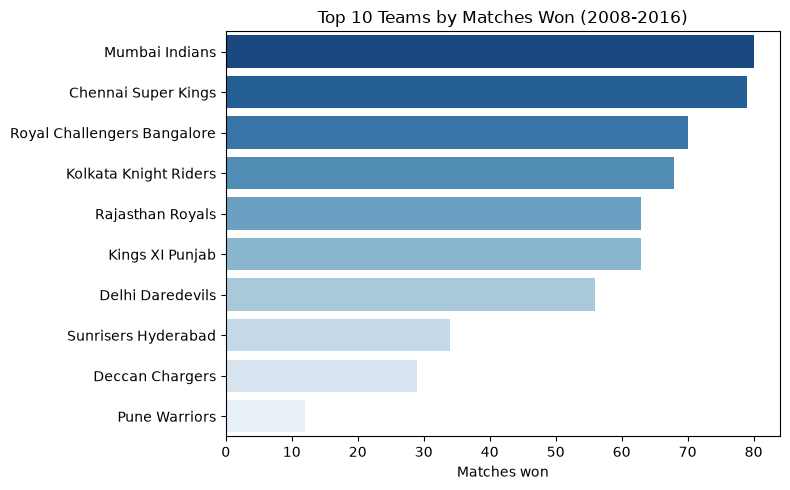

In [26]:
# Chart 1: Bar chart -- matches won per team (top 10)
top_teams = ipl_clean["winner"].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_teams.values, y=top_teams.index, hue=top_teams.index, palette="Blues_r", legend=False)
plt.title("Top 10 Teams by Matches Won (2008-2016)")
plt.xlabel("Matches won"); plt.ylabel("")
plt.tight_layout()
plt.show()

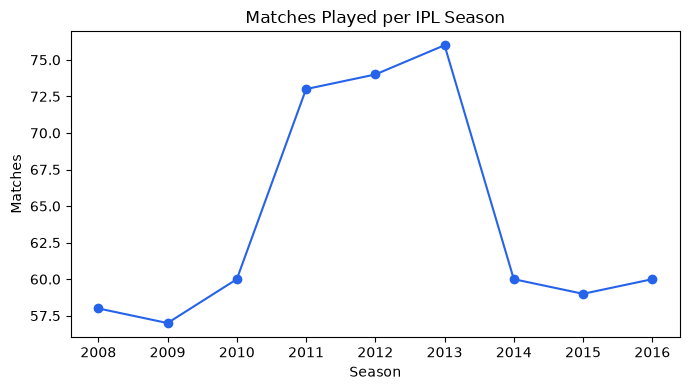

In [27]:
# Chart 2: Line chart -- number of matches played per season
matches_per_season = ipl_clean.groupby("season")["id"].count()

plt.figure(figsize=(7, 4))
plt.plot(matches_per_season.index, matches_per_season.values, marker="o", color="#2563eb")
plt.title("Matches Played per IPL Season")
plt.xlabel("Season"); plt.ylabel("Matches")
plt.tight_layout()
plt.show()

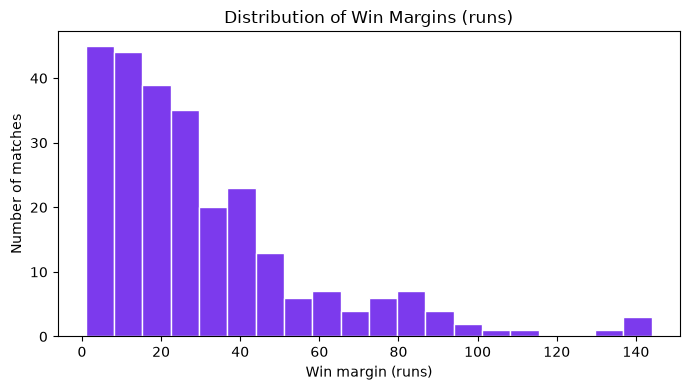

In [28]:
# Chart 3: Histogram -- distribution of win margins (by runs, excluding 0 = wicket wins)
runs_wins = ipl_clean.loc[ipl_clean["win_by_runs"] > 0, "win_by_runs"]

plt.figure(figsize=(7, 4))
plt.hist(runs_wins, bins=20, color="#7c3aed", edgecolor="white")
plt.title("Distribution of Win Margins (runs)")
plt.xlabel("Win margin (runs)"); plt.ylabel("Number of matches")
plt.tight_layout()
plt.show()

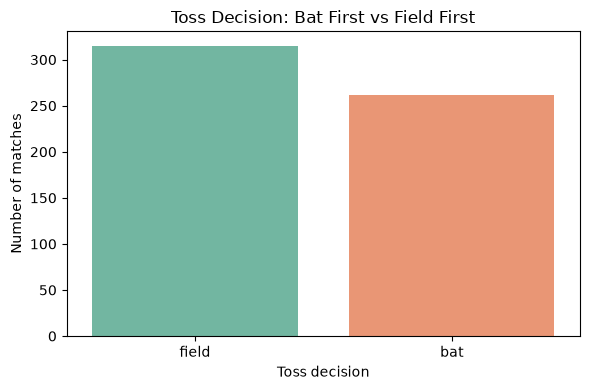

In [29]:
# Chart 4: Countplot -- toss decision (bat vs field) across all matches
plt.figure(figsize=(6, 4))
sns.countplot(data=ipl_clean, x="toss_decision", hue="toss_decision",
              palette="Set2", legend=False)
plt.title("Toss Decision: Bat First vs Field First")
plt.xlabel("Toss decision"); plt.ylabel("Number of matches")
plt.tight_layout()
plt.show()

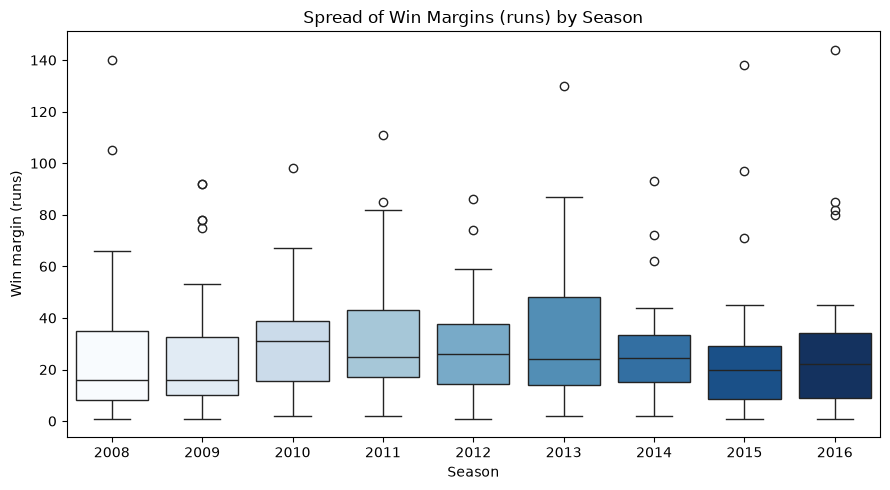

In [30]:
# Chart 5: Boxplot -- win margin (runs) by season, to see how competitiveness changed over time
plt.figure(figsize=(9, 5))
sns.boxplot(data=ipl_clean[ipl_clean["win_by_runs"] > 0], x="season", y="win_by_runs",
            hue="season", palette="Blues", legend=False)
plt.title("Spread of Win Margins (runs) by Season")
plt.xlabel("Season"); plt.ylabel("Win margin (runs)")
plt.tight_layout()
plt.show()

In [31]:
toss_equals_match_winner = (ipl_clean["toss_winner"] == ipl_clean["winner"]).mean() * 100
print(f"The toss winner also won the match in {toss_equals_match_winner:.1f}% of matches.")

The toss winner also won the match in 50.4% of matches.
